# Import

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import smplotlib

findfont: Failed to find font weight normal, now using 500.


# Path and constants

In [38]:
gotberg19_path = Path("/Users/dexbhadra/Documents/delphi/delphi25_valentin/600_trees/goetberg19")
sb99_path = Path("/Users/dexbhadra/Documents/delphi/published_runs_SB99")
pysb_path = Path("/Users/dexbhadra/Documents/delphi/delphi25_valentin/strippers/data_pysb99/pysb99")

metallicities = ["0.014", "0.006", "0.002", "0.0002"]                         # the four G19 metallicities (0.014 = solar)
suffix = {"0.014": "014", "0.006": "006", "0.002": "002", "0.0002": "0002"}   # file name endings of nbrs*.dat and q*.dat
c_A = 2.99792458e18            # speed of light [Angstrom / s]
eV_A = 12398.42                # photon energy E [eV] = 12398.42 / wavelength [A]
lam_H = 911.75                 # hydrogen ionization edge [A] (13.6 eV)

Z_color = {"0.014": "#D60270", "0.006": "#9B4F96", "0.002": "#0038A8", "0.0002": "#000000"}   # bisexual flag + black
single_color = {2: "#870047", 5: "#9B4F96", 10: "#0038A8"}                                      # bisexual flag
age_color = {11: "#FF218C", 20: "#FFD800", 50: "#21B1FF", 100: "#000000"}                       # pansexual flag + black

# Reading the files

* nbrs*.dat: number of stripped stars present after the burst, against time.
* q*.dat: $\log_{10}$ of the ionizing photon rates Q0 (H), Q1 (He I), Q2 (He II) after the burst; $-30$ means no stripped stars.
* sed/SED_Z*_starburst.txt and `_constant.txt: the stripped-star spectrum $L_\lambda$ [erg/s/Å], 100-10 000 Å, at 500 times
  from 1 Myr to 3 Gyr. The first row holds the wavelengths, every other row one time.

In [39]:
def read_counts(Z):
    names = ["time", "total", "caseA", "caseB", "BCEE", "above10", "above5", "above3"]
    return pd.read_csv(gotberg19_path / f"nbrs{suffix[Z]}.dat", sep=r"\s+", comment="#", names=names)

def read_q(Z):
    # the photon rates Q0 (H), Q1 (He I), Q2 (He II) [1/s] after a 1e6 Msun burst.
    # log10 Q = -30 when there are no stripped stars, so 10**(-30) is effectively zero.
    q = pd.read_csv(gotberg19_path / f"q{suffix[Z]}.dat", sep=r"\s+", comment="#", names=["time", "Q0", "Q1", "Q2"])
    q[["Q0", "Q1", "Q2"]] = 10.0 ** q[["Q0", "Q1", "Q2"]]
    return q

def read_spectra(path):
    # first row: 0, then the wavelengths [A]; 
    #every other row: time [yr], then L_lambda [erg/s/A] at each wavelength
    table = pd.read_csv(path, sep=r"\s+", comment="#", header=None).to_numpy()
    return table[1:, 0], table[0, 1:], table[1:, 1:]          # time, wavelength, luminosity (time x wavelength)

# The G19 stripped-star spectra used in the plots below are the burst files, SED_Z*_starburst.txt (G19's CDS files):
burst, constant = {}, {}
for Z in metallicities:
    burst[Z] = read_spectra(gotberg19_path / "sed" / f"SED_Z{Z}_starburst.txt")
    constant[Z] = read_spectra(gotberg19_path / "sed" / f"SED_Z{Z}_constant.txt")

# Number of stripped stars

After a burst of $10^6\,M_\odot$. Dotted lines: one and two DELPHI steps (29.6 and 59.2 Myr).

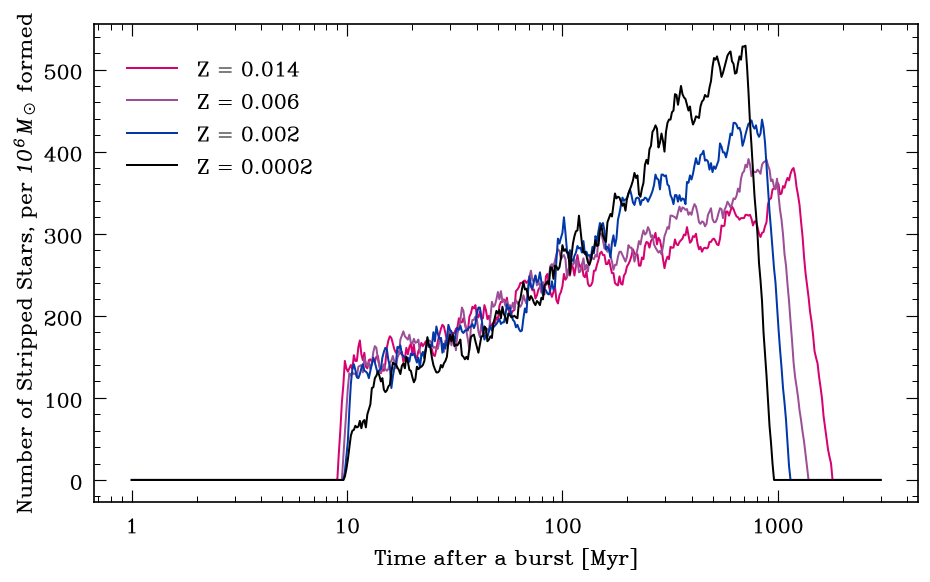

In [40]:
fig, ax = plt.subplots(figsize=(8,5))
for Z in metallicities:
    counts = read_counts(Z)
    ax.plot(counts["time"] / 1e6, counts["total"], color=Z_color[Z], label=f"Z = {Z}")
ax.set_xscale("log")
ax.set_xlabel("Time after a burst [Myr]")
ax.set_ylabel(r"Number of Stripped Stars, per $10^6\,M_\odot$ formed")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# The whole population: single + stripped stars

G19's Fig. 7 shows the whole population: the single stars (Starburst99) plus the stripped stars. 

* These files give $\log_{10} L_\lambda$ for **constant** star formation at 1 $M_\odot$/yr. The light of a $10^6\,M_\odot$ burst at age $t$
  is $10^6$ times how fast that light grows: $L_{\rm burst}(t) = 10^6 \times [L_{\rm const}(t + 0.05\,{\rm Myr}) - L_{\rm const}(t - 0.05\,{\rm Myr})] / 0.1\,{\rm Myr}$.
* Starburst99 metallicities, as in G19 (Sect. 2.3 and Table 2): 0.014, 0.008, 0.002, 0.001 for the stripped stars at 0.014, 0.006, 0.002, 0.0002.
* Single stars only: 2, 5 and 10 Myr. Single + stripped stars: 11, 20, 50 and 100 Myr.
* Grey band: AGN, $L_\nu \propto \nu^{\alpha}$ with $-2 < \alpha < -1.2$. Dotted lines: the ionization edges of H (13.6 eV),
  He I (24.6 eV) and He II (54.4 eV). The regions under the spectra are not shaded.

In [41]:
sb99_file = {"0.014": "run_Z014/SED_SB99_Z0.014_constant.txt",
             "0.006": "run_Z006/SED_SB99_Z0.008_constant.txt",
             "0.002": "run_Z002/SED_SB99_Z0.002_constant.txt",
             "0.0002": "run_Z0002/SED_SB99_Z0.001_constant.txt"}

In [42]:
pysb_Z = {"0.014": "0.014", "0.006": "0.006", "0.002": "0.002", "0.0002": "0.0004"}

In [43]:
# Both return the single stars of a 1e6 Msun burst at age_yr: wavelength [A] and L_lambda [erg/s/A]
def sb99_single(Z, age_yr):
    # Starburst99 gives a constant SFR of 1 Msun/yr. The light of a 1e6 Msun burst at age t is
    table = pd.read_csv(sb99_path / sb99_file[Z], sep=r"\s+", comment="#", header=None).to_numpy()
    time, wave, log_L = table[1:, 0], table[0, 1:], table[1:, 1:]
    L_const = 10**log_L
    L_const[log_L <= 0] = 0                 # file header: "values that are very low (=1) are actually zero"
    L_after = np.array([np.interp(age_yr + 0.05e6, time, L) for L in L_const.T])
    L_before = np.array([np.interp(age_yr - 0.05e6, time, L) for L in L_const.T])
    return wave, 1e6 * (L_after - L_before) / 0.1e6

def pysb_single(Z, age_yr):
    # pySB99 is run for a 1e6 Msun burst directly; take the time closest to age_yr (every 0.1 Myr)
    folder = pysb_path / f"Z{pysb_Z[Z]}"
    time = np.loadtxt(folder / "SED_times.txt")
    wave = np.loadtxt(folder / "SED_wavelength.txt")
    log_L = np.load(folder / "pySB_SED_stellar.npy")          # log10 L_lambda (time x wavelength)
    return wave, 10**log_L[np.argmin(np.abs(time - age_yr))]


def to_g19_grid(wave, wave_s, L_s):
    # put single-star L_s (on wave_s) on the G19 wavelengths 
    ion, ion_s = wave <= lam_H, wave_s <= lam_H
    return np.where(ion, np.interp(wave, wave_s[ion_s], L_s[ion_s]), np.interp(wave, wave_s[~ion_s], L_s[~ion_s]))


def plot_single(ax, wave, L_lambda, color, label, ls="-"):
    # draw log10(L_nu / L_nu(13.6 eV)) against photon energy
    energy = eV_A / wave
    L_nu = L_lambda * wave**2 / c_A
    ion = energy >= 13.6                                              # L_nu(13.6 eV) from the ionizing side of the edge
    L_at_13_6 = np.interp(13.6, energy[ion][::-1], L_nu[ion][::-1])   # [::-1]: np.interp needs increasing energy
    ax.plot(energy, np.log10(np.maximum(L_nu / L_at_13_6, 1e-10)), color=color, ls=ls, lw=1.2, label=label)

In [44]:
def plot_population_shape(ax, Z, single_stars):
    # single_stars: sb99_single or pysb_single
    time, wave, L_strip = burst[Z]          # stripped stars: G19's burst spectra; everything is drawn on these wavelengths
    # AGN: L_nu proportional to nu^-1.2 ... nu^-2 (grey band)
    E_agn = np.linspace(13.6, 90, 100)
    ax.fill_between(E_agn, -2.0 * np.log10(E_agn / 13.6), -1.2 * np.log10(E_agn / 13.6), color="#D9D9D9", lw=0, label="AGN")

    # young ages: single stars only
    for age_myr, color in single_color.items():
        #The star unpacks the tuple into two distinct argments of wavelengths and luminosities
        plot_single(ax, wave, to_g19_grid(wave, *single_stars(Z, age_myr * 1e6)), color, f"{age_myr} Myr, single")

    # later ages: single + stripped stars
    for age_myr, color in age_color.items():
        row = np.argmin(np.abs(time - age_myr * 1e6))              # the stripped-star time closest to this age
        L_total = to_g19_grid(wave, *single_stars(Z, age_myr * 1e6)) + L_strip[row]
        plot_single(ax, wave, L_total, color, f"{age_myr} Myr")

    # ionization edges of H, He I and He II
    for edge_eV in [13.6, 24.6, 54.4]:
        ax.axvline(edge_eV, color="gray", ls=":", lw=0.8)

    ax.set_xlim(10, 90)
    ax.set_ylim(-3, 0.5)
    ax.text(0.95, 0.92, f"Z = {Z}", transform=ax.transAxes, ha="right", fontsize=14)


def plot_population(single_stars, title, file_name):
    # 2 rows, 2 columns: one panel per metallicity
    fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
    for ax, Z in zip(axes.ravel(), metallicities):
        plot_population_shape(ax, Z, single_stars)

    for ax in axes[1, :]:
        ax.set_xlabel("energy [eV]")
    axes[1, 0].set_xticks(np.arange(10, 81, 10))      # leave out 90 on the left, so it does not touch the 10 of the right panel
    for ax in axes[:, 0]:
        ax.set_ylabel(r"log$_{10}$(L$_\nu$ / L$_\nu$(13.6 eV))")
    axes[1, 1].legend(frameon=False, title="years after burst", ncol=2, fontsize=10, loc="lower right")    # the empty corner of the Z = 0.0002 panel
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

In [45]:
sb99_file

{'0.014': 'run_Z014/SED_SB99_Z0.014_constant.txt',
 '0.006': 'run_Z006/SED_SB99_Z0.008_constant.txt',
 '0.002': 'run_Z002/SED_SB99_Z0.002_constant.txt',
 '0.0002': 'run_Z0002/SED_SB99_Z0.001_constant.txt'}

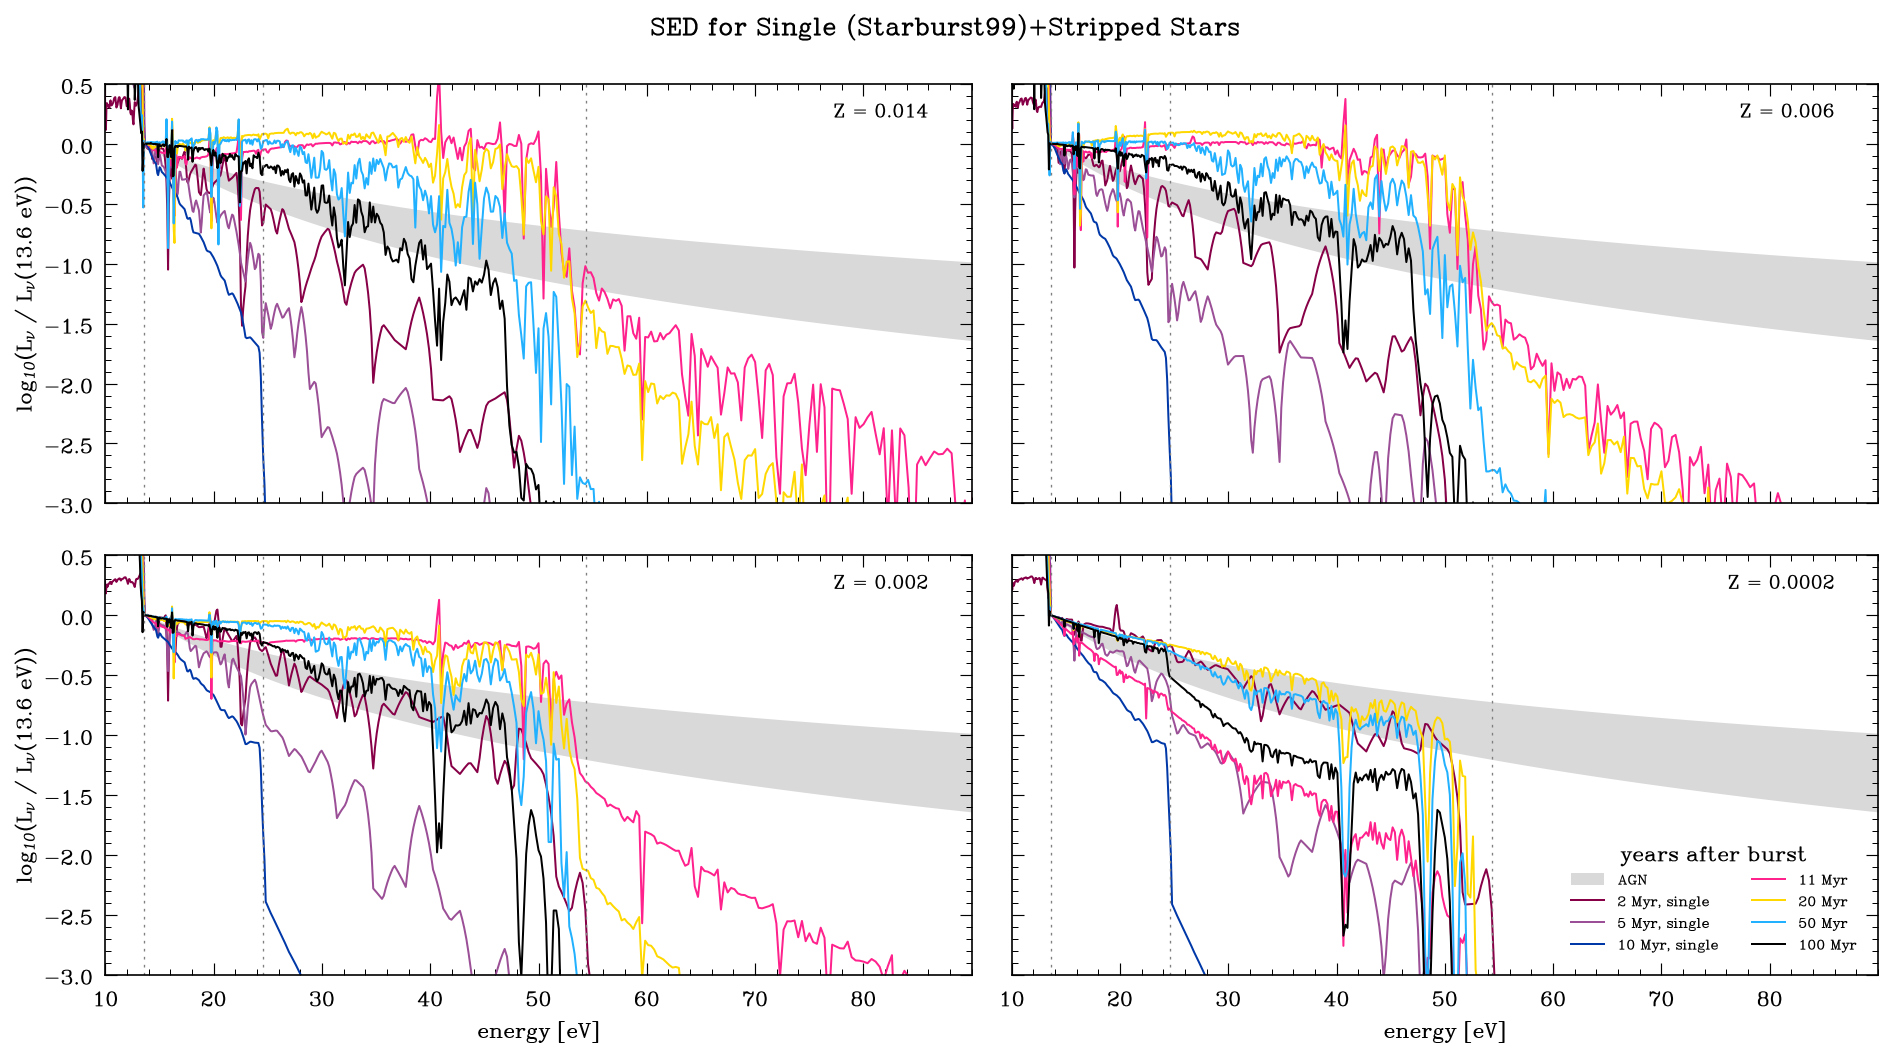

In [46]:
plot_population(sb99_single, "SED for Single (Starburst99)+Stripped Stars", "g19_fig7_population.png")

# The whole population with pySB99 single stars

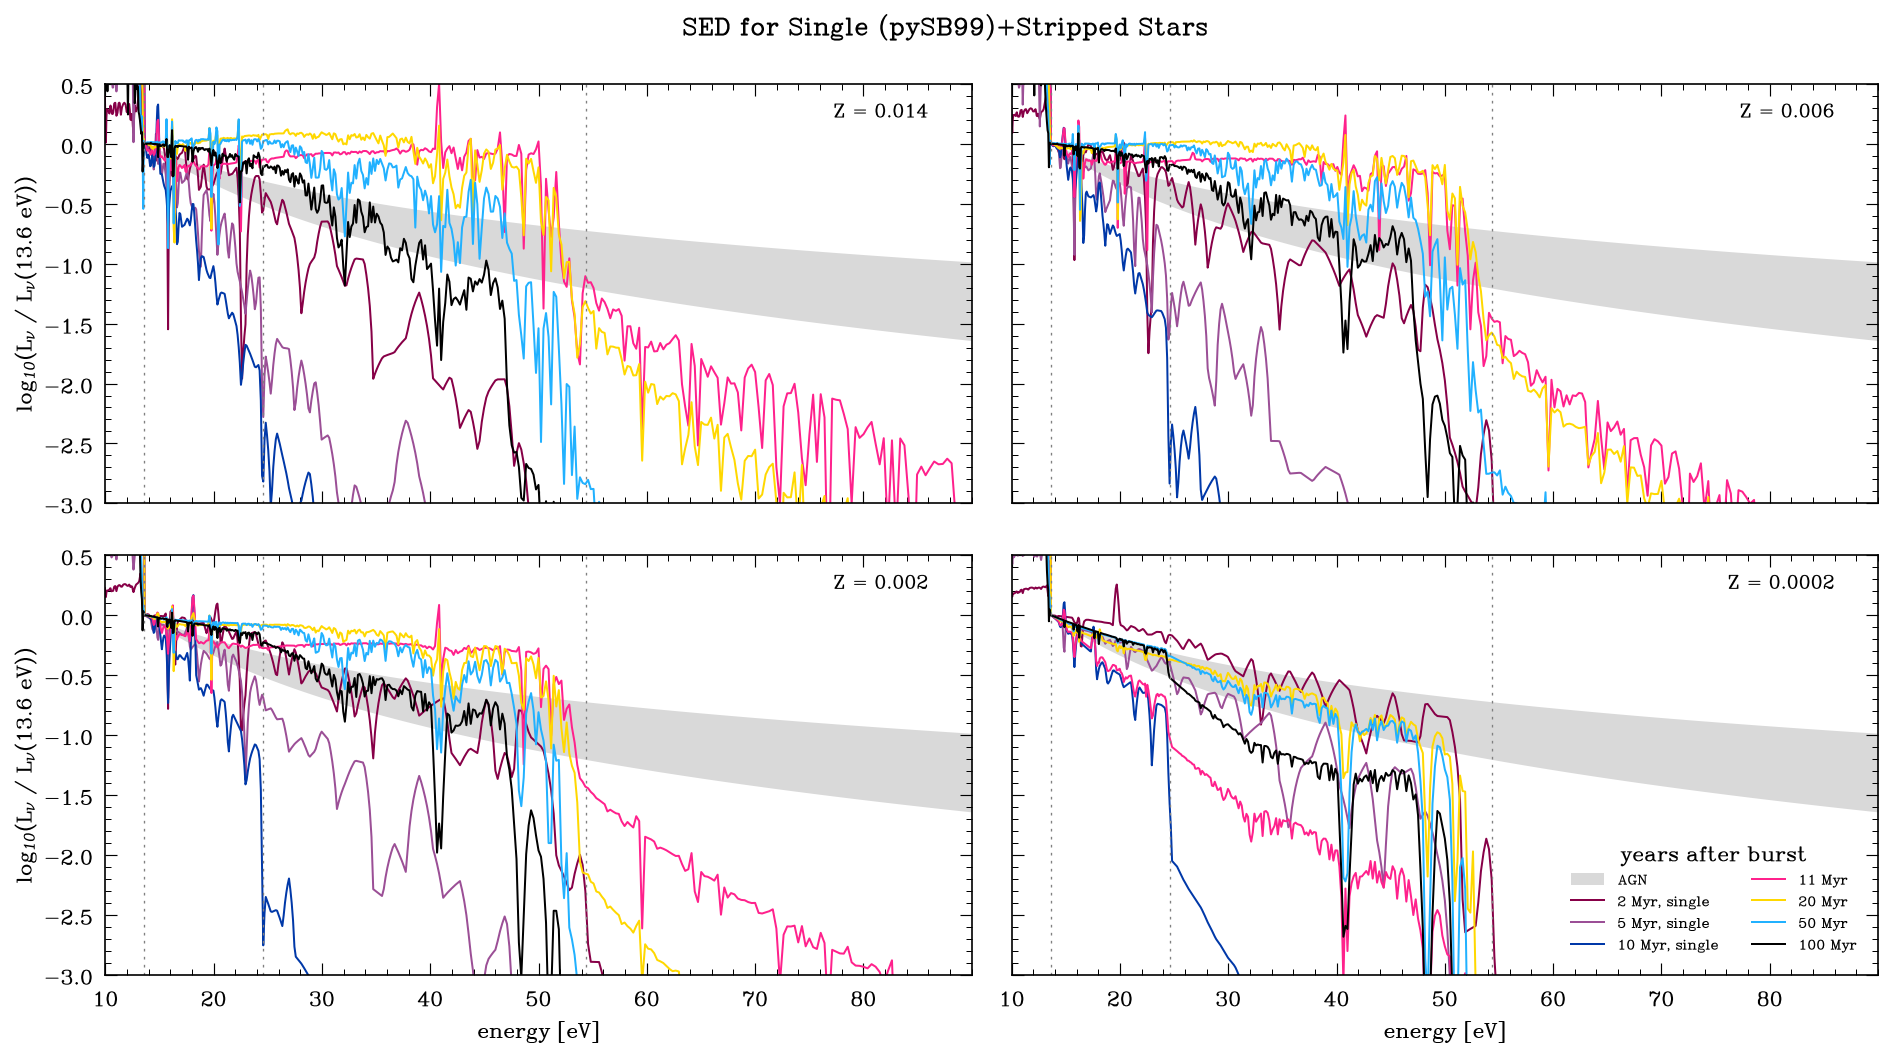

In [47]:
plot_population(pysb_single, "SED for Single (pySB99)+Stripped Stars", "g19_fig7_population_pysb.png")

# Single stars: Starburst99 vs pySB99

The single-star spectra of a $10^6\,M_\odot$ burst at 2, 5 and 10 Myr (before stripped stars contribute)

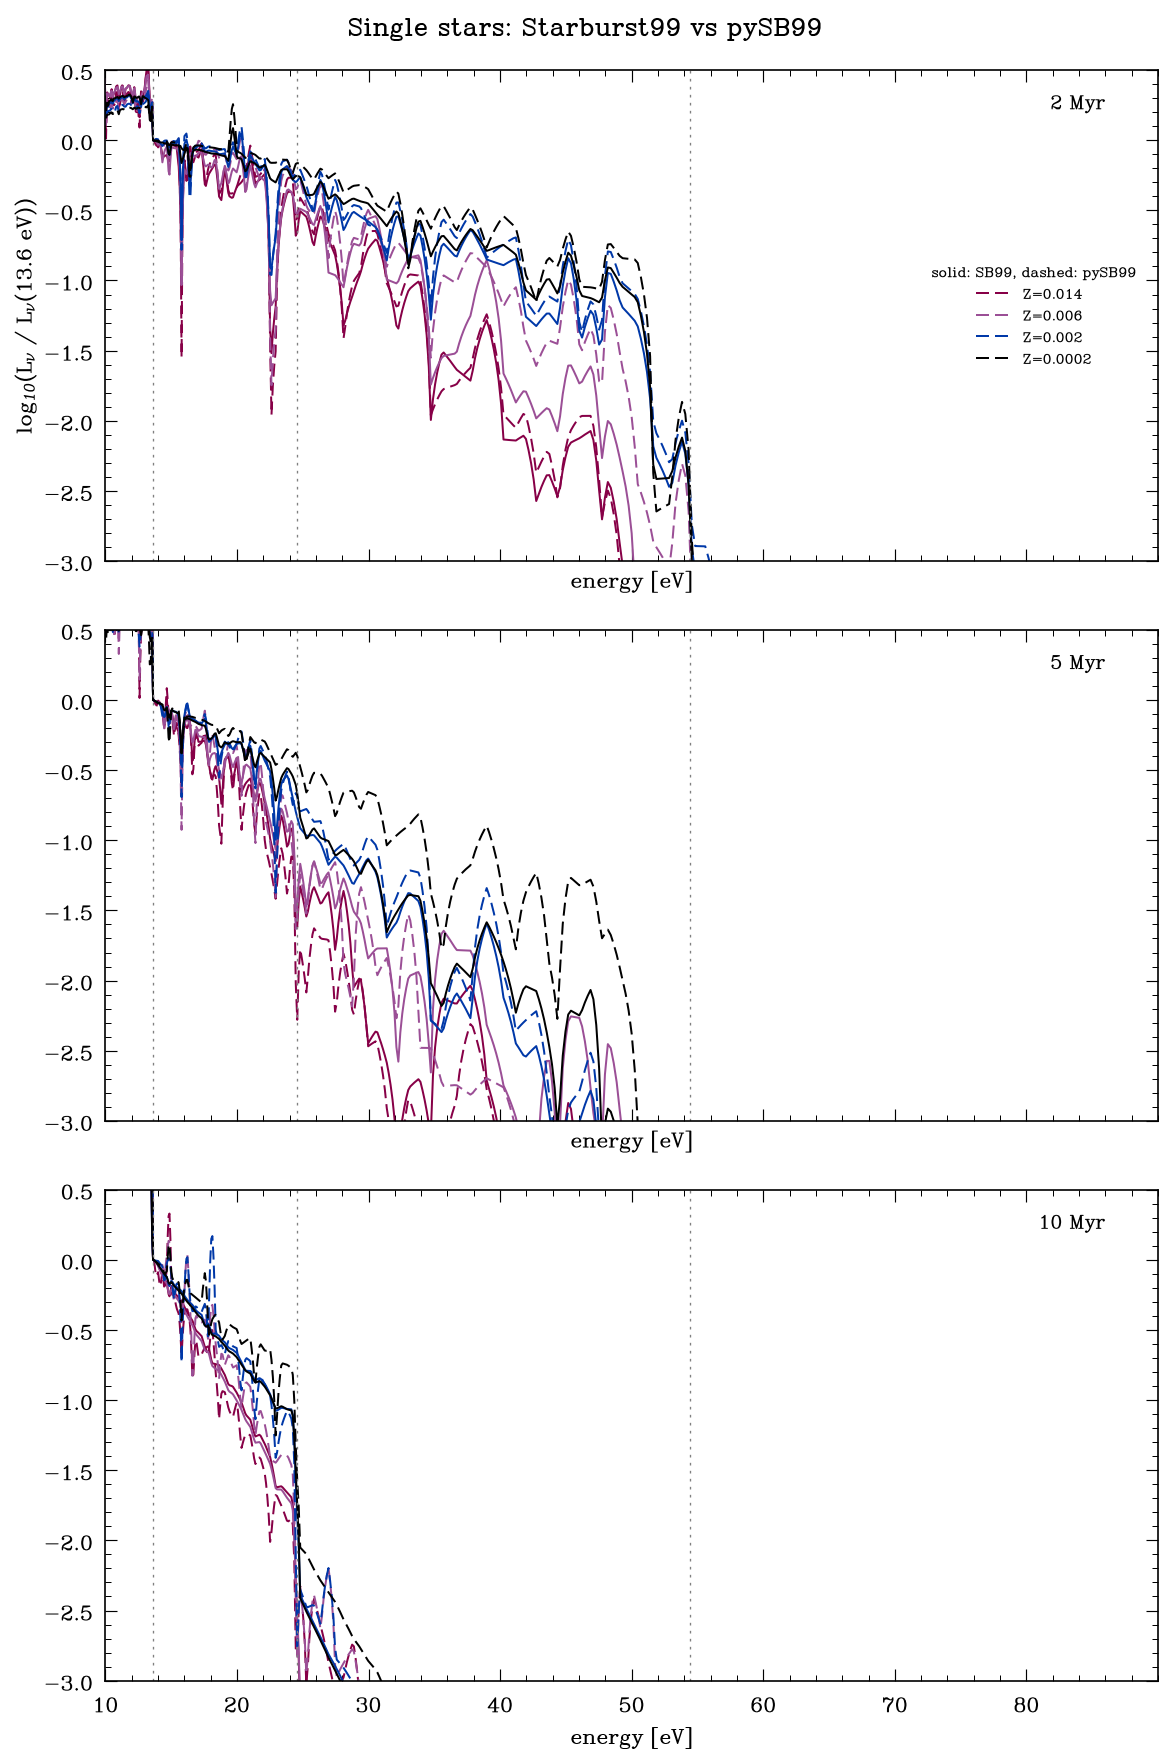

In [50]:
metal_color = {"0.014": "#870047", "0.006": "#9B4F96", "0.002": "#0038A8", "0.0002": "black"}   # bisexual flag + black

def plot_single_comparison(ax, age_myr):
    # one panel: Starburst99 (solid) and pySB99 (dashed) single stars at age_myr, for each metallicity
    for Z, color in metal_color.items():
        wave = burst[Z][1]                  # draw on the G19 wavelengths, as in the population figures
        plot_single(ax, wave, to_g19_grid(wave, *pysb_single(Z, age_myr * 1e6)), color, label = rf'Z={Z}', ls="--")
        plot_single(ax, wave, to_g19_grid(wave, *sb99_single(Z, age_myr * 1e6)), color, label = None)

    # ionization edges of H, He I and He II
    for edge_eV in [13.6, 24.6, 54.4]:
        ax.axvline(edge_eV, color="gray", ls=":", lw=0.8)
    ax.set_xlim(10, 90)
    ax.set_ylim(-3, 0.5)
    ax.set_xlabel("energy [eV]")
    ax.text(0.95, 0.92, f"{age_myr} Myr", transform=ax.transAxes, ha="right", fontsize=14)


# 1 row, 3 columns: one panel per age
fig, axes = plt.subplots(3, 1, figsize=(10, 15), sharex=True, sharey=True)
for ax, age_myr in zip(axes, [2, 5, 10]):
    plot_single_comparison(ax, age_myr)
axes[0].set_xticks(np.arange(10, 81, 10))         # leave out 90, so it does not touch the 10 of the next panel
axes[0].set_ylabel(r"log$_{10}$(L$_\nu$ / L$_\nu$(13.6 eV))")
axes[0].legend(frameon=False, fontsize=10, loc="center right", title="solid: SB99, dashed: pySB99", title_fontsize=10)
fig.suptitle("Single stars: Starburst99 vs pySB99")
fig.tight_layout()
fig.savefig("pysb99_vs_sb99.png", dpi=200)
plt.show()